In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score,
    GridSearchCV, cross_validate
)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())


(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [3]:

y = df["resolution_hours"]

features = ["complexity_score", "team_experience_years"]
X = df[features].copy()


if X.isnull().any().any() or y.isnull().any():
    raise ValueError("Handle missing values before training.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 192
Testing samples: 48


In [4]:

def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }, predictions


results = []
predictions = {}

# Baseline model
baseline = DummyRegressor(strategy="mean")

metrics, pred = evaluate_model(
    "Mean Baseline", baseline,
    X_train, X_test, y_train, y_test
)

results.append(metrics)
predictions["Mean Baseline"] = pred

print(pd.DataFrame(results).round(4))


           Model    MAE     RMSE     R2
0  Mean Baseline  9.114  10.5977 -0.021


In [5]:
linear_model = LinearRegression()

metrics, pred = evaluate_model(
    "Linear Regression", linear_model,
    X_train, X_test, y_train, y_test
)

results.append(metrics)
predictions["Linear Regression"] = pred

print(pd.DataFrame(results).round(4))


               Model    MAE     RMSE     R2
0      Mean Baseline  9.114  10.5977 -0.021
1  Linear Regression  2.906   3.5723  0.884


In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

polynomial_models = {}
cv_results = []

for degree in [2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        }
    )

    cv_results.append({
        "Degree": degree,
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Mean CV R2": scores["test_r2"].mean()
    })

    polynomial_models[degree] = model

cv_table = pd.DataFrame(cv_results)
print(cv_table.round(4))

# Choose the degree with the lowest average CV RMSE
best_degree = int(
    cv_table.loc[cv_table["Mean CV RMSE"].idxmin(), "Degree"]
)

print("Selected polynomial degree:", best_degree)

best_poly = polynomial_models[best_degree]

metrics, pred = evaluate_model(
    f"Polynomial Degree {best_degree}", best_poly,
    X_train, X_test, y_train, y_test
)

results.append(metrics)
predictions[f"Polynomial Degree {best_degree}"] = pred


   Degree  Mean CV MAE  Mean CV RMSE  Mean CV R2
0       2       3.1313        3.8325      0.8437
1       3       3.1620        3.8766      0.8407
Selected polynomial degree: 2


In [7]:
alpha_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    param_grid=alpha_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)
best_ridge = ridge_search.best_estimator_

print("Best Ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

metrics, pred = evaluate_model(
    "Ridge", best_ridge,
    X_train, X_test, y_train, y_test
)

results.append(metrics)
predictions["Ridge"] = pred


lasso_search = GridSearchCV(
    make_pipeline(
        StandardScaler(),
        Lasso(max_iter=20000)
    ),
    param_grid={
        "lasso__alpha": [0.001, 0.01, 0.1, 1, 10]
    },
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)
best_lasso = lasso_search.best_estimator_

print("Best Lasso alpha:", lasso_search.best_params_["lasso__alpha"])
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

metrics, pred = evaluate_model(
    "Lasso", best_lasso,
    X_train, X_test, y_train, y_test
)

results.append(metrics)
predictions["Lasso"] = pred


Best Ridge alpha: 0.1
Best Ridge CV RMSE: 3.9092037889673357
Best Lasso alpha: 0.001
Best Lasso CV RMSE: 3.909251978309689


In [8]:

results_df = pd.DataFrame(results)

print("Final test-set comparison:")
display(
    results_df.sort_values("RMSE").round(4).reset_index(drop=True)
)


Final test-set comparison:


,Model,MAE,RMSE,R2
0,Ridge,2.9059,3.5721,0.8840
1,Linear Regression,2.9060,3.5723,0.8840
2,Lasso,2.9061,3.5723,0.8840
3,Polynomial Degree 2,3.0202,3.7409,0.8728
4,Mean Baseline,9.1140,10.5977,-0.0210


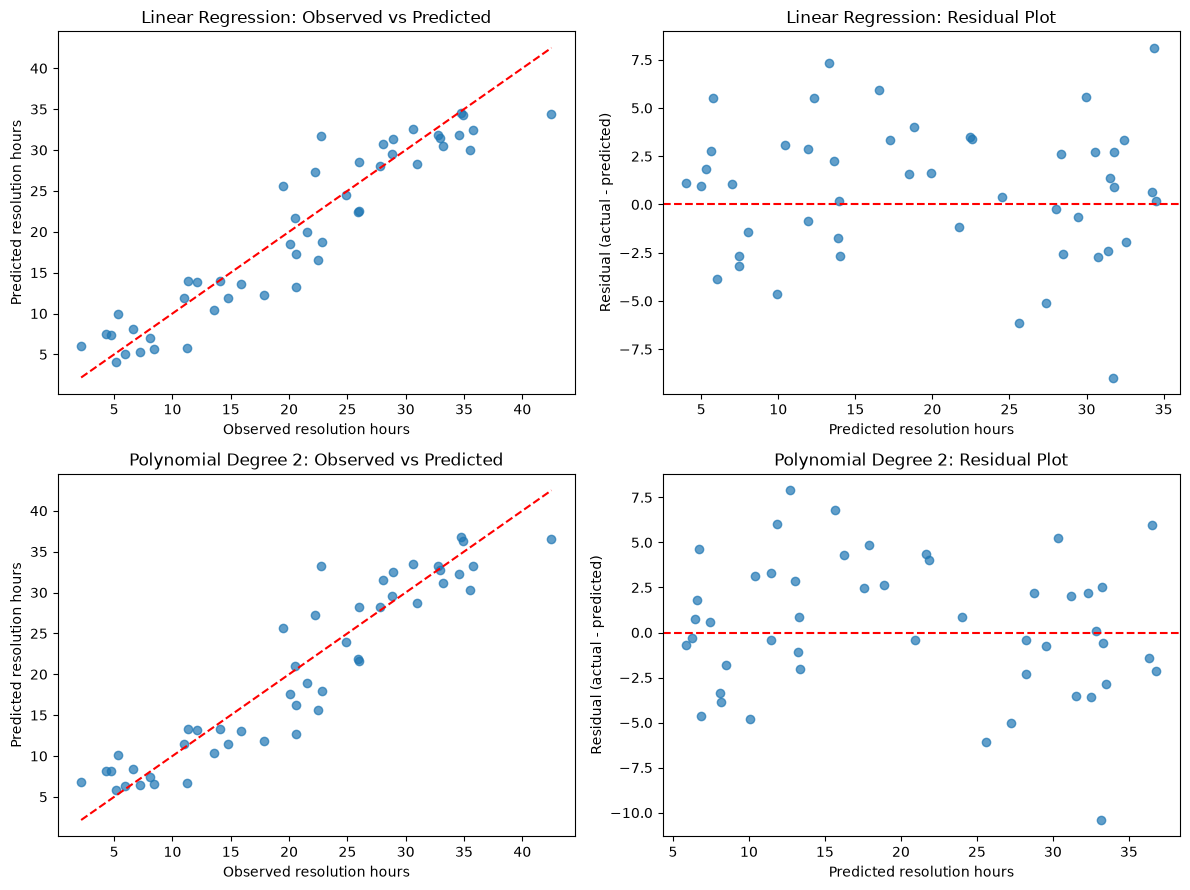

In [11]:

models_to_plot = [
    "Linear Regression",
    f"Polynomial Degree {best_degree}"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for row, name in enumerate(models_to_plot):
    actual = np.asarray(y_test)
    predicted = np.asarray(predictions[name])
    residuals = actual - predicted

    # Observed versus predicted
    axes[row, 0].scatter(actual, predicted, alpha=0.7)

    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())

    axes[row, 0].plot(
        [lower, upper], [lower, upper], "r--"
    )
    axes[row, 0].set_title(f"{name}: Observed vs Predicted")
    axes[row, 0].set_xlabel("Observed resolution hours")
    axes[row, 0].set_ylabel("Predicted resolution hours")

    # Residual plot
    axes[row, 1].scatter(predicted, residuals, alpha=0.7)
    axes[row, 1].axhline(0, color="red", linestyle="--")
    axes[row, 1].set_title(f"{name}: Residual Plot")
    axes[row, 1].set_xlabel("Predicted resolution hours")
    axes[row, 1].set_ylabel("Residual (actual - predicted)")

plt.tight_layout()
plt.show()


In [10]:

ridge_model = best_ridge.named_steps["ridge"]
lasso_model = best_lasso.named_steps["lasso"]

coefficient_comparison = pd.DataFrame({
    "Feature": features,
    "Ridge coefficient": ridge_model.coef_,
    
    "Lasso coefficient": lasso_model.coef_
})

print(coefficient_comparison.round(4))

print(
    "\nRidge coefficient L2 norm:",
    np.linalg.norm(ridge_model.coef_)
)

print(
    "Lasso coefficient L1 norm:",
    np.abs(lasso_model.coef_).sum()
)


                 Feature  Ridge coefficient  Lasso coefficient
0       complexity_score             8.9901             8.9938
1  team_experience_years            -1.0773            -1.0768

Ridge coefficient L2 norm: 9.054469146060757
Lasso coefficient L1 norm: 10.070675500367896


#Analysis Questions

10. Why is the mean baseline useful even though it ignores all features?
    The average baseline is helpful because it gives us a model to compare with other models. It guesses the time it takes to solve each ticket without using any information. If our other models do better than the baseline, it shows the information helps us make guesses. In our test, the baseline had more mistakes than Linear Regression, so using the information made the guesses better

11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?

    In my experiment, Ridge Regression had the lowest MAE of 2.9059 hours and the lowest RMSE of 3.5721 hours. Both metrics selected Ridge, but its performance was almost the same as Linear Regression. MAE measures the average absolute error, while RMSE gives more weight to large errors. Because of this, the two metrics can sometimes select different models.

12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?

In my experiment adding features did not make the model better. Linear Regression gave an RMSE of 3.5723 and an MAE of 2.9060. Polynomial Regression with degree 2 gave an RMSE of 3.7409 and an MAE of 3.0202. Cross‑validation showed that degree 2 was a little better than degree 3, with RMSEs of 3.8325 and 3.8766.

Usually degree 2 polynomial features help when the link between input features and the target is nonlinear. Adding more features does not always help the model. If the data already has an almost linear link the extra polynomial terms may give no information and can make the model more complicated.

In this dataset, Linear Regression did better on the test set. One possible reason is that the extra polynomial terms did not capture patterns. However, these results alone do not prove that the data was made to favour degree 1 or that overfitting really happened. To look deeper, I would check the feature relationships. Compare training and validation errors. Therefore, I chose Linear Regression because Linear Regression is simpler and did better on the test set.

13. How did regularization affect performance and coefficient magnitudes?
    
    Ridge and Lasso are both regularised forms of Linear Regression. They are used to control the size of the model’s coefficients, which helps reduce the chance of overfitting. Ridge shrinks the coefficients. Usually does not set them exactly to zero. Lasso, on the other hand, can drive some coefficients all the way to zero, which helps in selecting the most important features.

In my experiment, Ridge had an RMSE of 3.5721. Linear Regression had an RMSE of 3.5723, and Lasso also had an RMSE of 3.5723. The results from all three models are the same. Ridge performed a tiny bit better, but the difference is so small it might be due to chance. This shows that regularisation didn’t make a difference in this case. The dataset might not have had strong multicollinearity or overfitting issues to begin with. So the simpler Linear Regression model worked as well as the regularised versions.

14. Why is scaling included in the Ridge/Lasso pipeline?
    Feature scaling is important because the input features can have different ranges. In my dataset, complexity_score ranges from 1 to 10, while team_experience_years ranges from 0.5 to 12. StandardScaler transforms the features to have a mean of approximately 0 and a standard deviation of 1. This helps Ridge and Lasso apply regularization more fairly to the features. I used a pipeline so that scaling was included during model training.

15. Identify one potential leakage issue in the dataset and explain how you handled it.

I chose complexity_score and team_experience_years as my input features because they are available right when a ticket is created. Lines_changed usually only becomes known after developers start working on the ticket. Reopened is only known after the ticket has been resolved once. Using data that comes later could lead to data leakage if we’re trying to predict resolution time from the start. So I left out lines_changed and reopened. I also left out ticket_id because it’s an identifier and doesn’t help predict anything.

16. Would a random split be appropriate if tickets were collected over several years or came from repeatedcustomers/teams? Explain.

   A random train-test split works well when each data point stands alone and comes from the type of distribution. In my experiment I used an eighty to twenty percent train-test split with a state of 42 to keep the results reproducible.

However if the dataset contains tickets that were collected over years, a random split might not show how the model will perform on new tickets in the future.
In that case, a chronological split would be a choice. If many tickets belong to the customer or team a group-based split can also help keep information leakage from happening.

17. What additional tests would you perform before deploying this model?
   
    Before deploying the model, I would test it on real ticket data and evaluate its performance on new, unseen tickets. I would also inspect residual plots to look for patterns, check for unusually large prediction errors, and verify that the model does not produce unrealistic negative resolution times. I would investigate whether the model performs differently for tickets of different complexity levels and monitor its performance after deployment. Since this experiment uses only 240 records, I would collect more data before relying on the model in a real software development environment.
    